In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score , confusion_matrix , ConfusionMatrixDisplay

#Loading the previous cleaned titanic dataset.
df = pd.read_csv("cleaned_dataset.csv")
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,65.6344,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [9]:
# Drop columns that are just labels and carry no pattern for the model
df = df.drop(columns=["PassengerId", "Name", "Ticket"])

# Models need numbers, so turn Sex and Embarked into 0/1 columns
df = pd.get_dummies(df, columns=["Sex", "Embarked"], drop_first=True, dtype=int)

# X = the inputs, y = the answer we want to predict
X = df.drop(columns="Survived")
y = df["Survived"]
print(X.dtypes)

KeyError: "['PassengerId', 'Name', 'Ticket'] not found in axis"

In [5]:
# 80% to train, 20% to test; random_state makes the split repeatable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (712, 8) Test: (179, 8)


In [6]:
# Create the model and let it learn from the training data
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [7]:
# Predict on passengers the model has never seen
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))

Accuracy: 0.804
F1-score: 0.755


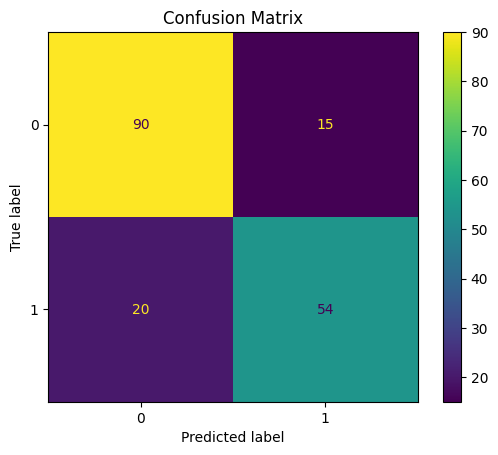

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# Confusion matrix: shows where the model was right and wrong
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
plt.title("Confusion Matrix")
plt.savefig("evaluation_plots.png")
plt.show()

from google.colab import files
files.download("evaluation_plots.png")